## Librerias

In [6]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

In [7]:
RAIZ = Path.cwd()

if not (RAIZ / "data").exists():
    RAIZ = RAIZ.parent

sys.path.insert(0, str(RAIZ / "src"))

from modelo_demanda import cargar_datos, entrenar_modelo

print("Carpeta del proyecto:", RAIZ)

Carpeta del proyecto: c:\kaido-motors


In [8]:
y, X = cargar_datos("MSUV")

y.head()

fecha
2001-01-01    3019
2001-02-01    3235
2001-03-01    3231
2001-04-01    3606
2001-05-01    3554
Freq: MS, Name: unidades, dtype: int64

In [9]:
calendario_A013 = pd.read_csv(
    RAIZ / "data" / "calendario_A013.csv"
)

calendario_A013

,t,periodo,anio,mes,dias_laborables,semana_santa
0,145,A0130101,A013,1,21,0
1,146,A0130201,A013,2,20,0
2,147,A0130301,A013,3,22,0
3,148,A0130401,A013,4,21,1
4,149,A0130501,A013,5,20,0
5,150,A0130601,A013,6,22,0
6,151,A0130701,A013,7,23,0
7,152,A0130801,A013,8,21,0
8,153,A0130901,A013,9,22,0
9,154,A0131001,A013,10,21,0


In [12]:
#Vamos a comprobarlo con el año 12

X[["paro", "confianza_consumidor"]].tail(3)

,paro,confianza_consumidor
fecha,,
2012-10-01,13.78,73.3
2012-11-01,13.78,77.4
2012-12-01,13.78,77.7


## Escenario central de A013

Preparo las variables que necesita el modelo para prever A013.
El calendario ya sabemos cual es. Para el paro y la confianza supongo
que se mantienen los valores de diciembre de A012: 13,78 % y 77,7.

Guardamos todo en `X_A013` para usarlo después en la previsión.

In [13]:
X_A013 = calendario_A013[
    ["dias_laborables", "semana_santa"]
].copy()

X_A013.index = pd.date_range(
    start="2013-01-01", periods=12, freq="MS"
)

X_A013["paro"] = X["paro"].iloc[-1]
X_A013["confianza_consumidor"] = X["confianza_consumidor"].iloc[-1]

X_A013 = X_A013[X.columns]

X_A013

,paro,confianza_consumidor,dias_laborables,semana_santa
2013-01-01,13.78,77.7,21,0
2013-02-01,13.78,77.7,20,0
2013-03-01,13.78,77.7,22,0
2013-04-01,13.78,77.7,21,1
2013-05-01,13.78,77.7,20,0
2013-06-01,13.78,77.7,22,0
2013-07-01,13.78,77.7,23,0
2013-08-01,13.78,77.7,21,0
2013-09-01,13.78,77.7,22,0
2013-10-01,13.78,77.7,21,0


In [14]:
import importlib
import modelo_demanda

importlib.reload(modelo_demanda)

print("Calculando la previsión de A013...", flush=True)

prevision_A013 = modelo_demanda.prever_modelo(
    y, X, X_A013
)

prevision_A013.round(0)

Calculando la previsión de A013...


2013-01-01    13310.0
2013-02-01    13529.0
2013-03-01    16951.0
2013-04-01    14798.0
2013-05-01    15422.0
2013-06-01    17512.0
2013-07-01    18308.0
2013-08-01    11268.0
2013-09-01    12343.0
2013-10-01    13837.0
2013-11-01    14595.0
2013-12-01    16539.0
Freq: MS, Name: predicted_mean, dtype: float64

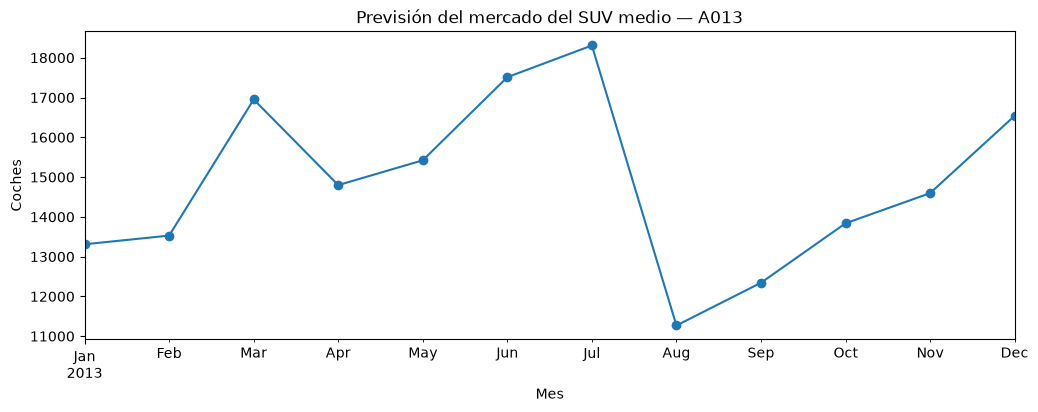

In [15]:
prevision_A013.plot(
    figsize=(12, 4),
    marker="o",
    title="Previsión del mercado del SUV medio — A013",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

La gráfica muestra un patrón claro que es ventas altas en primavera y comienzos del verano, caída en agosto y recuperación hacia diciembre

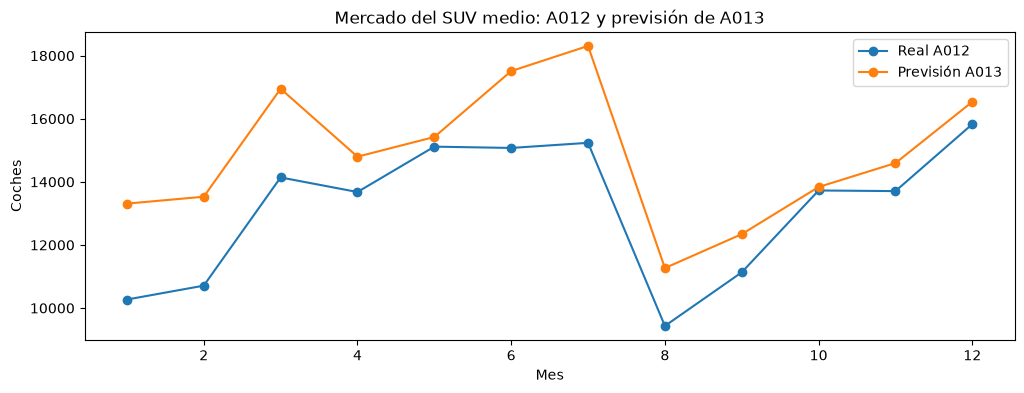

In [16]:
comparacion_anual = pd.DataFrame({
    "Real A012": y.loc["2012"].to_numpy(),
    "Previsión A013": prevision_A013.to_numpy()
}, index=range(1, 13))

comparacion_anual.plot(
    figsize=(12, 4),
    marker="o",
    title="Mercado del SUV medio: A012 y previsión de A013",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

## Crecimiento del año completo (AÑO 13)

In [17]:
totales = comparacion_anual.sum()

crecimiento = (
    totales["Previsión A013"] / totales["Real A012"] - 1
) * 100

print(totales.round(0))
print(f"Crecimiento previsto: {crecimiento:.1f}%")

Real A012         158056.0
Previsión A013    178412.0
dtype: float64
Crecimiento previsto: 12.9%
